# Лабораторная работа № 7. Разработка единого шаблона предварительной обработки данных
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение теоретических принципов и инструментальных средств для построения пайплайна для предварительной обработки данных.

**Задачи:** изучить предварительную обработку и её библиотеки; освоить масштабирование, представление категорий и построение пайплайна.


## 1. Локальный запуск и общий шаблон
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. Для работы № 9 в `environment.yml` добавлен `statsmodels=0.14`. Обновить окружение из корня можно командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Ноутбук работает из корня проекта и из `notebooks/`. RCAEval уже сохранён на компьютере; повторное скачивание не выполняется. Таблицы и рисунки записываются в папку этой работы внутри `reports/`.

**Пайплайн** — последовательность шагов, которая одинаково готовит обучающие данные и новые строки. Сначала отделяем проверочные данные, затем вызываем `fit` только для обучения. Для проверки используются сохранённые средние, масштаб и категории.

Подключаем библиотеки для таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем средства подготовки данных и регрессии.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.preprocessing import LabelEncoder, MinMaxScaler

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab07'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
EXAMPLES = ROOT / 'data/raw/pipeline_examples'
EXAMPLES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'statsmodels']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
pandas            2.3.3
numpy             2.2.6
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
statsmodels      0.14.6
Name: Версия, dtype: object

169

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Переиспользуемый шаблон подготовки
Для числовых столбцов заполняем пропуски средним значением обучения. Масштабирование можно включить или отключить. `StandardScaler` вычитает среднее и делит на стандартное отклонение.

Для категорий заполняем пропуски наиболее частой категорией и используем `OneHotEncoder`: отдельные столбцы 0/1. Одну категорию оставляем базовой (`drop='first'`), чтобы вместе со свободным членом не создавать избыточные столбцы. Названия преобразованных признаков сохраняются.

Эта функция одинаковая в работах № 7, 8 и 9. Для новой задачи меняются списки столбцов и последний шаг модели. Каждый ноутбук содержит её определение и запускается самостоятельно.

Определяем общий шаблон предварительной обработки.

In [6]:
def make_preprocessor(numeric, categorical, scale=True):
    numeric_steps = [('impute', SimpleImputer(strategy='mean'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), numeric),
        ('categorical', categorical_steps, categorical)
    ], verbose_feature_names_out=False).set_output(transform='pandas')

## 2. Учебная задача: общий шаблон
### 2.1. Загрузка Data.csv
Используем маленькую учебную таблицу с полями Country, Age, Salary и Purchased, которая показана на рис. 7.1. Country — категория страны, Age и Salary — числа, Purchased — ответ Yes/No. Это пример работы с пропусками и категориями, а не данные мониторинга.

В методичке встречается устаревший `Imputer`; в текущей библиотеке используем `SimpleImputer`. Сначала отделяем проверочные строки и затем обучаем подготовку.

Получаем учебный CSV, если его ещё нет на компьютере.

In [7]:
example_path = EXAMPLES / 'Data.csv'
example_revision = '66d3cdbd8a19102c54750d8e8bd834845c7eedef'
example_url = f'https://raw.githubusercontent.com/murphymv/Machine-Learning-A-Z/{example_revision}/Data.csv'
if not example_path.exists():
    example_path.write_bytes(urlopen(example_url, timeout=60).read())

Читаем учебную таблицу.

In [8]:
example = pd.read_csv(example_path)

Печатаем строки, типы и пропуски.

In [9]:
display(example)
display(pd.DataFrame({'Тип': example.dtypes, 'Пропуски': example.isna().sum()}))

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


,Тип,Пропуски
Country,object,0
Age,float64,1
Salary,float64,1
Purchased,object,0


В таблице пропущены возраст и зарплата в отдельных строках. Страну не превращаем в числовой порядок: вместо этого создаём признаки 0/1. Ответ Purchased кодируется отдельно.

Кодируем ответ No/Yes и выделяем признаки.

In [10]:
label_encoder = LabelEncoder()
example_y = pd.Series(label_encoder.fit_transform(example.Purchased), index=example.index, name='Purchased')
example_X = example[['Age', 'Salary', 'Country']]
print('Коды ответов:', dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Коды ответов: {'No': np.int64(0), 'Yes': np.int64(1)}


Отделяем 20% строк для проверки.

In [11]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    example_X, example_y, test_size=0.2, stratify=example_y, random_state=SEED)
print('Обучение:', len(Xe_train), '| Проверка:', len(Xe_test))

Обучение: 8 | Проверка: 2


Обучаем подготовку и преобразуем обе части.

In [12]:
example_prepare = make_preprocessor(['Age', 'Salary'], ['Country'])
example_train_ready = example_prepare.fit_transform(Xe_train)
example_test_ready = example_prepare.transform(Xe_test)

Показываем результат заполнения, масштаба и кодирования.

In [13]:
display(example_train_ready)
display(example_test_ready)
print('Средние для заполнения:', example_prepare.named_transformers_['numeric'].named_steps['impute'].statistics_)
print('Базовая страна:', example_prepare.named_transformers_['categorical'].named_steps['encode'].categories_[0][0])

,Age,Salary,Country_Germany,Country_Spain
3,-2.670638e-01,-0.341743,0.0,1.0
8,1.458579e+00,1.537844,1.0,0.0
0,5.957577e-01,0.598050,0.0,0.0
6,-1.021786e-15,-1.110665,0.0,1.0
7,1.170972e+00,1.196101,0.0,0.0
9,-4.108674e-01,0.170872,0.0,0.0
5,-6.984745e-01,-0.598050,0.0,0.0
1,-1.848903e+00,-1.452408,0.0,1.0


,Age,Salary,Country_Germany,Country_Spain
2,-1.417492,-0.939793,1.0,0.0
4,0.020543,0.000000,1.0,0.0


Средние для заполнения: [3.98571429e+01 6.50000000e+04]
Базовая страна: France


Числа Age и Salary теперь находятся в сопоставимом масштабе. Пропуски заполнены средними обучающих строк. Страна представлена двумя столбцами: третья, базовая, задаётся двумя нулями. Коды Purchased не входят в признаки. На маленьком примере проверяем преобразования; LinearRegression далее испытываем на настоящем числовом ответе RCAEval.

Сравниваем стандартизацию и масштабирование в диапазон 0–1.

In [14]:
filled_train = SimpleImputer(strategy='mean').fit_transform(Xe_train[['Age', 'Salary']])
standardized = StandardScaler().fit_transform(filled_train)
normalized_range = MinMaxScaler().fit_transform(filled_train)
display(pd.DataFrame({'Возраст после StandardScaler': standardized[:, 0],
                      'Возраст после MinMaxScaler': normalized_range[:, 0]}))

,Возраст после StandardScaler,Возраст после MinMaxScaler
0,-2.670638e-01,0.478261
1,1.458579e+00,1.000000
2,5.957577e-01,0.739130
3,-1.021786e-15,0.559006
4,1.170972e+00,0.913043
5,-4.108674e-01,0.434783
6,-6.984745e-01,0.347826
7,-1.848903e+00,0.000000


StandardScaler задаёт среднее 0 и стандартное отклонение 1 на обучении. MinMaxScaler помещает обучающие значения в диапазон 0–1. Здесь под нормализацией показано именно изменение диапазона; нормализация длины вектора — другая операция.

## 3. Индивидуальное задание: подготовка данных мониторинга

### 3.1. Прежний набор данных
RCAEval содержит измерения микросервисов Online Boutique во время одного CPU-эксперимента. Используем тот же сценарий из первой работы. Новые сценарии не добавляем. Единицы отдельных показателей в локальном файле не указаны: сохраняем исходные шкалы или явно подписываем деление на миллион.


Читаем сохранённое имя сценария.

In [15]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем локальные метрики и время внесения сбоя.

In [16]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Показываем первые строки и размер таблицы.

In [17]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Тип сбоя:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1, '| Пропусков:', int(df.isna().sum().sum()))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Тип сбоя: cpu
Строк: 1441 | Метрик: 72 | Пропусков: 4


### 3.2. Категориальный признак
В исходной таблице метрики разных сервисов разложены по столбцам. Перестраиваем её: одна строка теперь соответствует **сервису в один момент времени**. Значения метрик остаются прежними. Название сервиса — настоящая категория.

Берём сервисы с медианной задержкой и их CPU, память, socket и workload. Ответ для проверки LinearRegression — медианная задержка того же сервиса в тот же момент. Она не входит в признаки. Такой формат позволяет выполнить обработку категорий и реальных пропусков на прежнем датасете.

Создаём таблицу «сервис — момент времени».

In [18]:
services = sorted(column.removesuffix('_latency-50') for column in df.columns if column.endswith('_latency-50'))
parts = []
for service in services:
    part = df[['time']].copy()
    for metric in ['cpu', 'mem', 'socket', 'workload']:
        part[metric] = df[f'{service}_{metric}']
    part['latency'] = df[f'{service}_latency-50']
    part['service'] = service
    parts.append(part)
long_data = pd.concat(parts, ignore_index=True)

Печатаем новую таблицу, пропуски и число строк по сервисам.

In [19]:
display(long_data.head())
display(long_data.isna().sum().rename('Пропуски'))
display(long_data.service.value_counts().rename('Измерений'))
print('Строк после представления по сервисам:', len(long_data))

,time,cpu,mem,socket,workload,latency,service
0,1705353846,0.685023,111521792.0,4.0,14.000,0.002971,adservice
1,1705353847,0.685023,111521792.0,4.0,14.267,0.002969,adservice
2,1705353848,0.582707,111521792.0,4.0,14.267,0.002969,adservice
3,1705353849,0.625903,111521792.0,4.0,14.267,0.002969,adservice
4,1705353850,0.613414,111521792.0,4.0,14.267,0.002969,adservice


time        0
cpu         1
mem         0
socket      0
workload    0
latency     0
service     0
Name: Пропуски, dtype: int64

service
adservice                1441
cartservice              1441
checkoutservice          1441
currencyservice          1441
emailservice             1441
frontend                 1441
paymentservice           1441
productcatalogservice    1441
recommendationservice    1441
shippingservice          1441
Name: Измерений, dtype: int64

Строк после представления по сервисам: 14410


Число строк увеличилось, потому что один исходный момент представлен отдельно для каждого выбранного сервиса. Это не новые измерения. Redis не имеет нужной задержки и сюда не входит; часть исходных пропусков относится к другим метрикам. В новой таблице сохранён настоящий пропуск CPU recommendationservice.

Строим график количества измерений по сервисам.

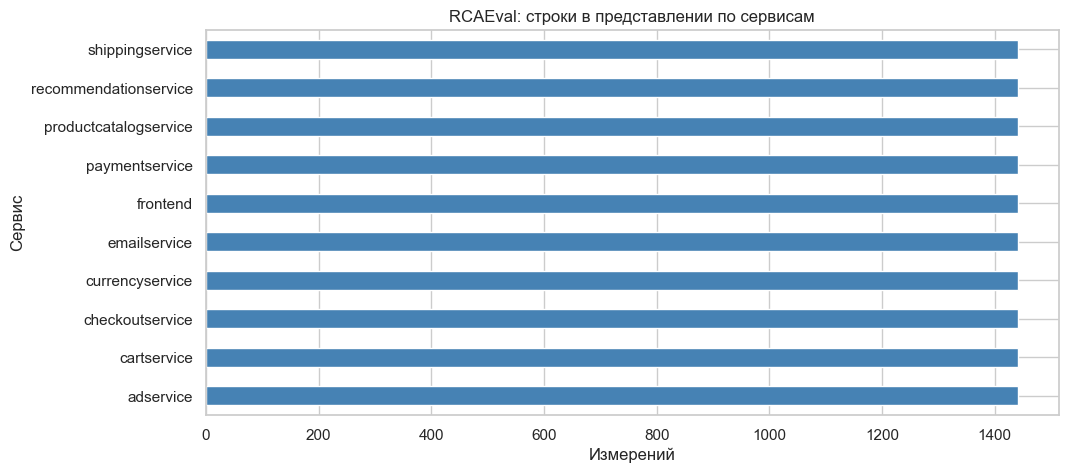

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
long_data.service.value_counts().sort_index().plot.barh(ax=ax, color='steelblue')
ax.set(title='RCAEval: строки в представлении по сервисам', xlabel='Измерений', ylabel='Сервис')
save_show(fig, '01_rca_services.png')

Каждая полоса показывает число моментов для одного сервиса. Равные длины означают одинаковое покрытие времени. Это количество записей в одном эксперименте, а не число отдельных сбоев.

Строим исходные распределения четырёх числовых признаков.

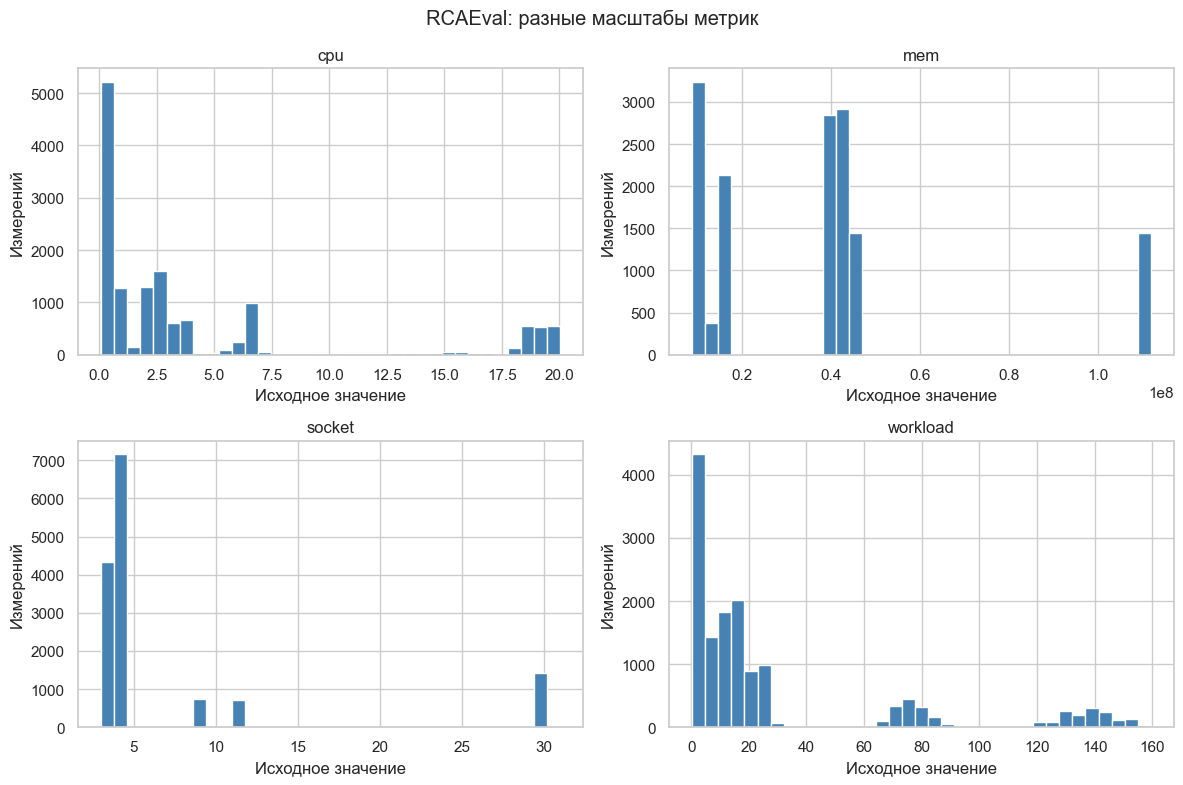

In [21]:
numeric = ['cpu', 'mem', 'socket', 'workload']
categorical = ['service']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, numeric):
    ax.hist(long_data[feature].dropna(), bins=35, color='steelblue')
    ax.set(title=feature, xlabel='Исходное значение', ylabel='Измерений')
fig.suptitle('RCAEval: разные масштабы метрик')
fig.tight_layout()
save_show(fig, '02_rca_raw_histograms.png')

По горизонтали стоит значение метрики, по вертикали — число строк. CPU, память, socket и workload имеют разные диапазоны. Графики объединяют сервисы: отдельные группы могут отражать различия между сервисами, а не аномалии. Один пропуск не участвует только в своей гистограмме.

Выбираем минутные участки по исходным моментам и разделяем все сервисы вместе.

In [22]:
minute_groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, period, minute_groups))
test_times = df.time.iloc[test_idx]
train_data = long_data.loc[~long_data.time.isin(test_times)]
test_data = long_data.loc[long_data.time.isin(test_times)]
X_train, X_test = train_data[numeric + categorical], test_data[numeric + categorical]
y_train, y_test = train_data.latency, test_data.latency
print('Обучение:', len(X_train), '| Проверка:', len(X_test))

Обучение: 11410 | Проверка: 3000


Все сервисы одного проверочного момента остаются в проверке. Минутные участки не смешиваются между частями. Время и известный период использованы для разделения; модель получает только четыре метрики и имя сервиса.

Обучаем общий шаблон и преобразуем данные.

In [23]:
prepare = make_preprocessor(numeric, categorical)
train_ready = prepare.fit_transform(X_train)
test_ready = prepare.transform(X_test)

Показываем реальные пропуски и заполненные значения в исходной шкале.

In [24]:
missing_rows = X_train.index[X_train[numeric].isna().any(axis=1)]
imputer = prepare.named_transformers_['numeric'].named_steps['impute']
filled_numeric = pd.DataFrame(imputer.transform(X_train[numeric]), index=X_train.index, columns=numeric)
display(X_train.loc[missing_rows])
display(filled_numeric.loc[missing_rows])
print('Пропусков после подготовки:', int(train_ready.isna().sum().sum() + test_ready.isna().sum().sum()))

,cpu,mem,socket,workload,service
11707,NaN,45068288.0,4.0,18.067,recommendationservice


,cpu,mem,socket,workload
11707,4.389737,45068288.0,4.0,18.067


Пропусков после подготовки: 0


Заполняется только копия, которая передаётся модели. Для каждой числовой метрики используется среднее обучающих строк всех выбранных сервисов. Это простая учебная стратегия; исходный Parquet не меняется. Категориальных пропусков здесь нет, но шаблон содержит и такой шаг.

Показываем кодирование разных сервисов и подготовленные признаки.

In [25]:
representatives = X_train.drop_duplicates('service').index
print('Базовый сервис:', prepare.named_transformers_['categorical'].named_steps['encode'].categories_[0][0])
display(train_ready.loc[representatives])
print('Размеры:', train_ready.shape, test_ready.shape)

Базовый сервис: adservice


,cpu,mem,socket,workload,service_cartservice,service_checkoutservice,service_currencyservice,service_emailservice,service_frontend,service_paymentservice,service_productcatalogservice,service_recommendationservice,service_shippingservice
60,-0.626684,2.595473,-0.366136,-0.356534,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1501,-0.397224,0.220870,-0.366136,-0.113176,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2942,-0.645101,-0.895892,0.262909,-0.690553,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4383,2.316027,0.112270,-0.366136,0.989089,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5824,-0.665891,0.208136,-0.491945,-0.688955,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7265,0.290328,-0.736926,2.904895,-0.389936,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8706,-0.624629,0.051603,-0.491945,-0.690553,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
10147,-0.209638,-0.947831,-0.366136,2.741906,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
11588,-0.307601,0.273668,-0.366136,-0.275414,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
13029,-0.675008,-0.990469,-0.491945,-0.537859,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Размеры: (11410, 13) (3000, 13)


Четыре первых признака числовые, остальные показывают сервис столбцами 0/1. Базовый сервис соответствует нулям во всех столбцах категорий. Название сервиса не означает порядок или величину, поэтому числовые коды вроде 1, 2, 3 здесь не используются.

Сравниваем числовые признаки после масштабирования.

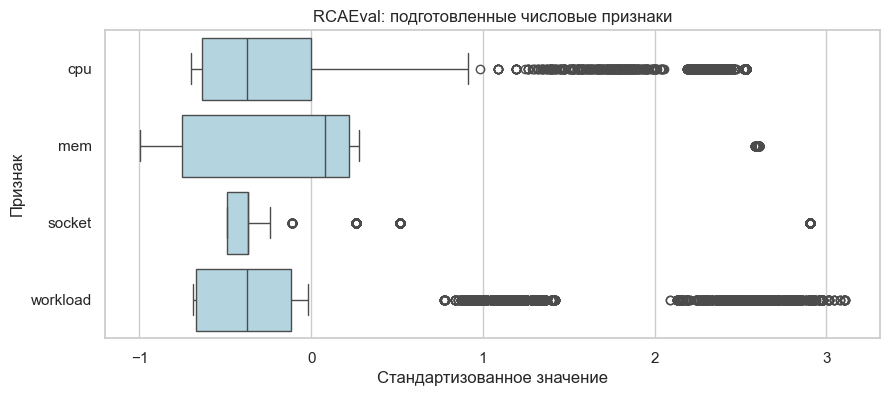

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=train_ready[numeric], orient='h', ax=ax, color='lightblue')
ax.set(title='RCAEval: подготовленные числовые признаки', xlabel='Стандартизованное значение', ylabel='Признак')
save_show(fig, '03_rca_scaled.png')

После подготовки значения имеют сопоставимый масштаб. Ящик показывает середину и разброс, отдельные точки — редкие значения по правилу boxplot. Масштабирование не убирает необычные измерения и не объявляет их ошибками. Большие пики могут остаться далеко от середины.

### 3.3. Проверка шаблона с LinearRegression

Определяем функцию расчёта ошибок регрессии.

In [27]:
def regression_scores(actual, predicted):
    return {'MSE': mean_squared_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted),
            'R2': r2_score(actual, predicted)}

Объединяем подготовку и линейную регрессию и обучаем модель.

In [28]:
model = Pipeline([('prepare', make_preprocessor(numeric, categorical)), ('regression', LinearRegression())])
model.fit(X_train, y_train)
prediction = model.predict(X_test)
mean_prediction = np.full(len(y_test), y_train.mean())
metrics = pd.DataFrame([regression_scores(y_test, mean_prediction), regression_scores(y_test, prediction)],
                       index=['Среднее обучения', 'LinearRegression'])
display(metrics)

,MSE,MAE,R2
Среднее обучения,0.010264,0.075802,-0.000002
LinearRegression,0.000579,0.006839,0.943596


Здесь LinearRegression проверяет работу всего шаблона на настоящем числовом ответе — задержке. MSE и MAE должны быть меньше для более точных ответов. R² сравнивает ответы с постоянным средним проверочной части; отдельно показан baseline по среднему обучения. Модель оценивает текущую задержку в одном сценарии.

Сравниваем настоящие и предсказанные задержки.

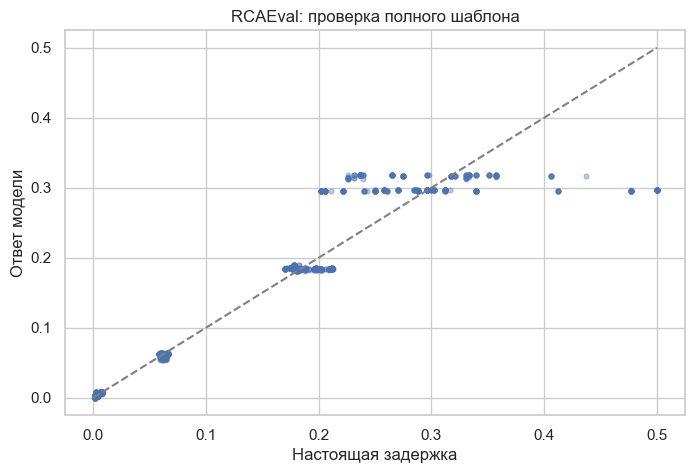

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_test, prediction, s=12, alpha=0.35)
low, high = min(y_test.min(), prediction.min()), max(y_test.max(), prediction.max())
ax.plot([low, high], [low, high], '--', color='gray')
ax.set(title='RCAEval: проверка полного шаблона', xlabel='Настоящая задержка', ylabel='Ответ модели')
save_show(fig, '04_rca_predictions.png')

Точка — измерение сервиса на отложенном участке. Пунктир означает точное совпадение. Чем дальше точка от него, тем больше ошибка. Объединение нескольких сервисов не делает линейную модель точным описанием всех их режимов.

Сохраняем подготовленные части и текст результата.

In [30]:
train_ready.to_csv(REPORT / 'train_prepared.csv', index_label='row')
test_ready.to_csv(REPORT / 'test_prepared.csv', index_label='row')
metrics.to_csv(REPORT / 'regression_metrics.csv', index_label='model')
pd.DataFrame({'row': test_data.index, 'time': test_data.time.to_numpy(), 'service': test_data.service.to_numpy(),
              'actual': y_test.to_numpy(), 'prediction': prediction}).to_csv(REPORT / 'predictions.csv', index=False)
analysis = (f'Изучил предварительную обработку на {case}. Представил {len(df)} моментов как {len(long_data)} строк для {len(services)} сервисов. '
            f'В выбранной таблице было {int(long_data.isna().sum().sum())} пропущенных значений; после подготовки пропусков нет. '
            f'Обучение содержит {len(X_train)} строк, проверка — {len(X_test)}. '
            'Выполнил заполнение пропусков, масштабирование и кодирование сервисов. Проверил общий шаблон с LinearRegression. '
            f'Проверочная MAE задержки: {metrics.loc["LinearRegression", "MAE"]:.4f} в исходной шкале.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'case': case, 'original_rows': len(df), 'services': services, 'long_rows': len(long_data),
           'missing_before': int(long_data.isna().sum().sum()), 'prepared_columns': train_ready.columns.tolist(),
           'train_rows': len(X_train), 'test_rows': len(X_test), 'regression': regression_scores(y_test, prediction)}

Изучил предварительную обработку на re2ob_checkoutservice_cpu_1. Представил 1441 моментов как 14410 строк для 10 сервисов. В выбранной таблице было 1 пропущенных значений; после подготовки пропусков нет. Обучение содержит 11410 строк, проверка — 3000. Выполнил заполнение пропусков, масштабирование и кодирование сервисов. Проверил общий шаблон с LinearRegression. Проверочная MAE задержки: 0.0068 в исходной шкале.

Сохраняем сведения об исходных файлах и список рисунков.

In [31]:
sources = {'example_url': example_url, 'example_revision': example_revision, 'rcaeval': selection,
           'sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                      for path in [example_path, metrics_path, inject_path]}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')
summary['figures'] = sorted(path.name for path in FIGURES.glob('*.png'))
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

1006

## 4. Заключение
Изучил теоретические принципы и инструментальные средства построения пайплайна для предварительной обработки данных. Научился загружать таблицы, разделять данные, заполнять пропуски, масштабировать числа и представлять категории столбцами 0/1.

Разработал общий шаблон подготовки и проверил его с линейной регрессией. На RCAEval использовал реальные измерения и названия сервисов. Обучающие параметры подготовки считаются только по обучающей части; сохранённые исходные данные остаются прежними.

## 5. Ответы на контрольные вопросы
**1. Какая библиотека управляет табличными наборами данных?**  
`pandas`. NumPy работает с массивами, scikit-learn — с подготовкой данных и моделями, Matplotlib — с графиками, OpenCV — прежде всего с изображениями.

**2. Какая стратегия обработки пропусков нежелательна?**  
В контексте предложенных вариантов — **б) безусловное удаление всех строк с пропусками**: можно потерять много данных и изменить состав выборки. Но универсального запрета на удаление нет: выбор зависит от причины пропусков и их количества. Среднее, медиану и частую категорию вычисляют по обучению.

**3. Нужно ли OneHotEncoder для целевого признака {C#, Java, Python, R}?**  
Для обычного одноклассового классификатора scikit-learn — нет: обычно подходит одна метка класса на строку, строковая или числовая. Если тот же столбец является **входным признаком**, OneHotEncoder подходит. В вопросе слово «независимая» противоречит слову «целевая»; выбор определяется ролью столбца.

**4. Как разделять данные и какое соотношение выбрать?**  
Обучение используется для настройки модели, проверка — для оценки её ответов. 20:80 и 25:75 часто подходят для учебных задач, но единственного оптимального отношения нет. 40:30 не задаёт полного разделения. Для временных данных важно также не смешивать похожие соседние записи; в RCAEval сохраняются минутные участки.

**5. Как читать CSV?**  
Вариант **а)** — `dataset = pd.read_csv('data.csv')` после `import pandas as pd`. Остальные предложенные записи не являются правильным чтением CSV через pandas.